In [1]:
import os
import numpy as np
import pandas as pd
from google.colab import drive

# 1. Montar Google Drive para acceder a los archivos
drive.mount('/content/drive')

# 2. Definir los marcadores
PROXIES_NULOS = ['SIN DATO', 'N/A', '-', '', 'nan', 'NAN', 'None']
print("¡Entorno configurado correctamente!")


Mounted at /content/drive
¡Entorno configurado correctamente!


In [3]:
# 1.
RUTA_ARCHIVO = 'DESERCION_DE_LA_FORMACIÓN_PROFESIONAL_INTEGRAL_20260629.csv'

# 2. Carga limpia declarando proxies de nulos

df = pd.read_csv(
    RUTA_ARCHIVO,
    dtype={'IDENTIFICADOR_UNICO_FICHA': str},
    na_values=PROXIES_NULOS,
    keep_default_na=True
)

# 3. Limpieza profunda de comillas y espacios en blanco
columnas_texto = df.select_dtypes(include=['object']).columns

for col in columnas_texto:
    if col != 'IDENTIFICADOR_UNICO_FICHA': # Protegemos la llave única
        # Quitamos comillas dobles, simples y espacios en los extremos
        df[col] = df[col].astype(str).str.replace('"', '').str.replace("'", "").str.strip()
        # Re-mapeamos los vacíos que hayan surgido tras limpiar las comillas
        df[col] = df[col].replace(['nan', 'None', ''], np.nan)

print("✅ ¡Archivo cargado localmente con éxito y textos normalizados sin comillas!")
print(f"El conjunto de datos tiene: {df.shape[0]} filas y {df.shape[1]} columnas.")



✅ ¡Archivo cargado localmente con éxito y textos normalizados sin comillas!
El conjunto de datos tiene: 42080 filas y 15 columnas.


In [4]:
# Buscaremos una columna que contenga el código 9514
columna_centro = [col for col in df.columns if 'CODIGO_CENTRO' in col.upper()]

if columna_centro:
    col_centro = columna_centro[0]
    # Filtramos por el código del centro (como texto o número)
    df_cimm = df[df[col_centro].astype(str).str.contains('9514')].copy()

    print(f"✅ Filtro aplicado con éxito usando la columna: '{col_centro}'")
    print(f"Filas originales: {df.shape[0]} ➡️ Filas del CIMM: {df_cimm.shape[0]}")
    print("\n📋 Columnas disponibles en tus datos para estructurar las fichas:")
    print(list(df_cimm.columns))
else:
    print("❌ No encontré una columna con la palabra 'CODIGO_CENTRO'. Por favor ejecuta: print(list(df.columns))")


✅ Filtro aplicado con éxito usando la columna: 'CODIGO_CENTRO'
Filas originales: 42080 ➡️ Filas del CIMM: 353

📋 Columnas disponibles en tus datos para estructurar las fichas:
['CODIGO_REGIONAL', 'NOMBRE_REGIONAL', 'CODIGO_CENTRO', 'NOMBRE_CENTRO', 'IDENTIFICADOR_UNICO_FICHA', 'FECHA_INICIO_FICHA', 'FECHA_TERMINACION_FICHA', 'CODIGO_PROGRAMA', 'VERSION_PROGRAMA', 'NOMBRE_PROGRAMA_FORMACION', 'NIVEL_FORMACION', 'MODALIDAD_FORMACION', 'TOTAL_APRENDICES_MATRICULADOS', 'DESERTORES_AÑO_ACTUAL', 'PERIODO']


In [6]:
# 1. Calcular la Tasa de Deserción por Ficha
df_cimm['TASA_DESERCION_FICHA'] = df_cimm['DESERTORES_AÑO_ACTUAL'] / df_cimm['TOTAL_APRENDICES_MATRICULADOS']

# 2. Definir el umbral principal (8.41%) y el alternativo (12.0%) sugeridos para sensibilidad
UMBRAL_PRINCIPAL = 0.0841
UMBRAL_ALTERNO = 0.1200

# 3. Crear las variables objetivo binarias
df_cimm['ALTA_DESERCION'] = (df_cimm['TASA_DESERCION_FICHA'] > UMBRAL_PRINCIPAL).astype(int)
df_cimm['ALTA_DESERCION_SENS'] = (df_cimm['TASA_DESERCION_FICHA'] > UMBRAL_ALTERNO).astype(int)

print("--- 📊 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO PRINCIPAL (> 8.41%) ---")
print(df_cimm['ALTA_DESERCION'].value_counts())
print(df_cimm['ALTA_DESERCION'].value_counts(normalize=True) * 100)

print("\n--- 🔍 TABLA CRUZADA: NIVEL DE FORMACIÓN VS PRESENCIA DE ALTA DESERCIÓN ---")
# Creamos la tabla cruzada
tabla_niveles = pd.crosstab(
    df_cimm['NIVEL_FORMACION'],
    df_cimm['ALTA_DESERCION'],
    margins=True,
    margins_name="Total Fichas"
)

# Calcular la tasa promedio de deserción real observada por cada nivel de formación
tasa_por_nivel = df_cimm.groupby('NIVEL_FORMACION')['TASA_DESERCION_FICHA'].mean() * 100
print("\nCantidad de fichas por categoría:")
print(tabla_niveles)
print("\nTasa promedio de deserción (%) por nivel de formación:")
print(tasa_por_nivel.round(2))


--- 📊 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO PRINCIPAL (> 8.41%) ---
ALTA_DESERCION
0    322
1     31
Name: count, dtype: int64
ALTA_DESERCION
0    91.21813
1     8.78187
Name: proportion, dtype: float64

--- 🔍 TABLA CRUZADA: NIVEL DE FORMACIÓN VS PRESENCIA DE ALTA DESERCIÓN ---

Cantidad de fichas por categoría:
ALTA_DESERCION     0   1  Total Fichas
NIVEL_FORMACION                       
CURSO ESPECIAL   117  23           140
EVENTO             1   0             1
OPERARIO           2   0             2
TECNICO          125   7           132
TECNOLOGO         77   1            78
Total Fichas     322  31           353

Tasa promedio de deserción (%) por nivel de formación:
NIVEL_FORMACION
CURSO ESPECIAL    9.84
EVENTO            0.00
OPERARIO          0.00
TECNICO           1.97
TECNOLOGO         0.69
Name: TASA_DESERCION_FICHA, dtype: float64


In [7]:
import pandas as pd
import numpy as np

# 1. Filtrar la población: Excluir EVENTO y OPERARIO por baja representatividad
niveles_a_excluir = ['EVENTO', 'OPERARIO']
df_modelo = df_cimm[~df_cimm['NIVEL_FORMACION'].isin(niveles_a_excluir)].copy()

print(f"✅ Población acotada. Registros restantes para el modelo: {df_modelo.shape[0]} fichas.")

# 2. Ingeniería de Detalles Temporales (Fechas de las fichas)
# Convertimos a formato fecha nativo de pandas
df_modelo['FECHA_INICIO_FICHA'] = pd.to_datetime(df_modelo['FECHA_INICIO_FICHA'], errors='coerce')
df_modelo['FECHA_TERMINACION_FICHA'] = pd.to_datetime(df_modelo['FECHA_TERMINACION_FICHA'], errors='coerce')

# Variable Derivada 1: Duración planeada de la ficha en días
df_modelo['DURACION_PLANEADA_DIAS'] = (df_modelo['FECHA_TERMINACION_FICHA'] - df_modelo['FECHA_INICIO_FICHA']).dt.days

# Variable Derivada 2: Días de exposición dentro del año analizado (asumiendo año base 2024)
# Evaluamos cuántos días estuvo activa la ficha durante el año 2024
inicio_2024 = pd.to_datetime('2024-01-01')
fin_2024 = pd.to_datetime('2024-12-31')

df_modelo['FECHA_MIN_EXPOSICION'] = df_modelo['FECHA_INICIO_FICHA'].apply(lambda x: max(x, inicio_2024) if pd.notnull(x) else x)
df_modelo['FECHA_MAX_EXPOSICION'] = df_modelo['FECHA_TERMINACION_FICHA'].apply(lambda x: min(x, fin_2024) if pd.notnull(x) else x)
df_modelo['DIAS_EXPOSICION_2024'] = (df_modelo['FECHA_MAX_EXPOSICION'] - df_modelo['FECHA_MIN_EXPOSICION']).dt.days

# Eliminamos las columnas auxiliares de fechas de exposición
df_modelo = df_modelo.drop(columns=['FECHA_MIN_EXPOSICION', 'FECHA_MAX_EXPOSICION'])

# 3. Eliminar variables que generan FUGA DE INFORMACIÓN (Data Leakage)
variables_fuga = ['DESERTORES_AÑO_ACTUAL', 'TASA_DESERCION_FICHA']
df_modelo = df_modelo.drop(columns=variables_fuga)

print("\n📋 Variables definitivas listas para el análisis bivariado:")
print(list(df_modelo.columns))


✅ Población acotada. Registros restantes para el modelo: 350 fichas.

📋 Variables definitivas listas para el análisis bivariado:
['CODIGO_REGIONAL', 'NOMBRE_REGIONAL', 'CODIGO_CENTRO', 'NOMBRE_CENTRO', 'IDENTIFICADOR_UNICO_FICHA', 'FECHA_INICIO_FICHA', 'FECHA_TERMINACION_FICHA', 'CODIGO_PROGRAMA', 'VERSION_PROGRAMA', 'NOMBRE_PROGRAMA_FORMACION', 'NIVEL_FORMACION', 'MODALIDAD_FORMACION', 'TOTAL_APRENDICES_MATRICULADOS', 'PERIODO', 'ALTA_DESERCION', 'ALTA_DESERCION_SENS', 'DURACION_PLANEADA_DIAS', 'DIAS_EXPOSICION_2024']


/tmp/ipykernel_379/589778808.py:12: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_modelo['FECHA_INICIO_FICHA'] = pd.to_datetime(df_modelo['FECHA_INICIO_FICHA'], errors='coerce')
/tmp/ipykernel_379/589778808.py:13: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_modelo['FECHA_TERMINACION_FICHA'] = pd.to_datetime(df_modelo['FECHA_TERMINACION_FICHA'], errors='coerce')


📊 ANALISIS BIVARIADO: NIVEL DE FORMACIÓN VS ALTA DESERCIÓN
ALTA_DESERCION   % Baja Deserción  % Alta Deserción
NIVEL_FORMACION                                    
CURSO ESPECIAL              83.57             16.43
TECNICO                     94.70              5.30
TECNOLOGO                   98.72              1.28


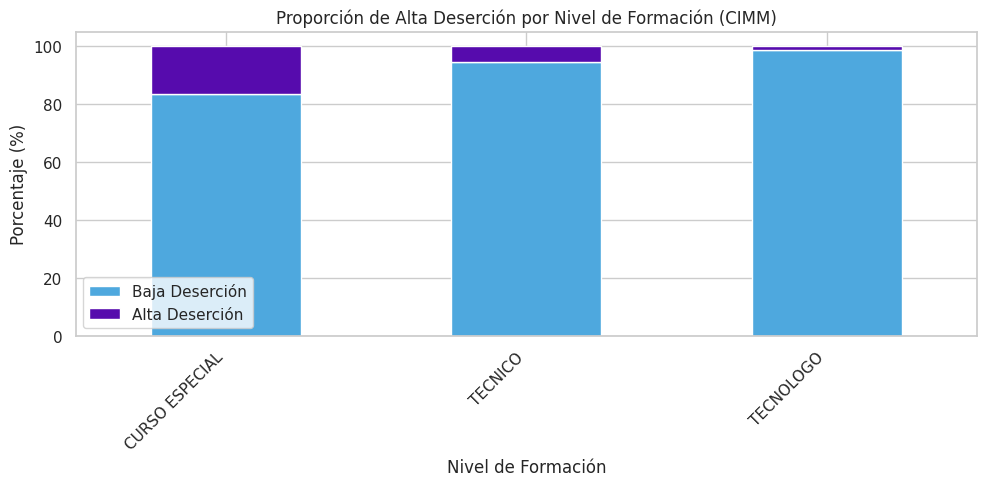


📊 ANALISIS BIVARIADO: MODALIDAD DE FORMACIÓN VS ALTA DESERCIÓN
ALTA_DESERCION       % Baja Deserción  % Alta Deserción
MODALIDAD_FORMACION                                    
PRESENCIAL                      94.18              5.82
VIRTUAL                         80.00             20.00


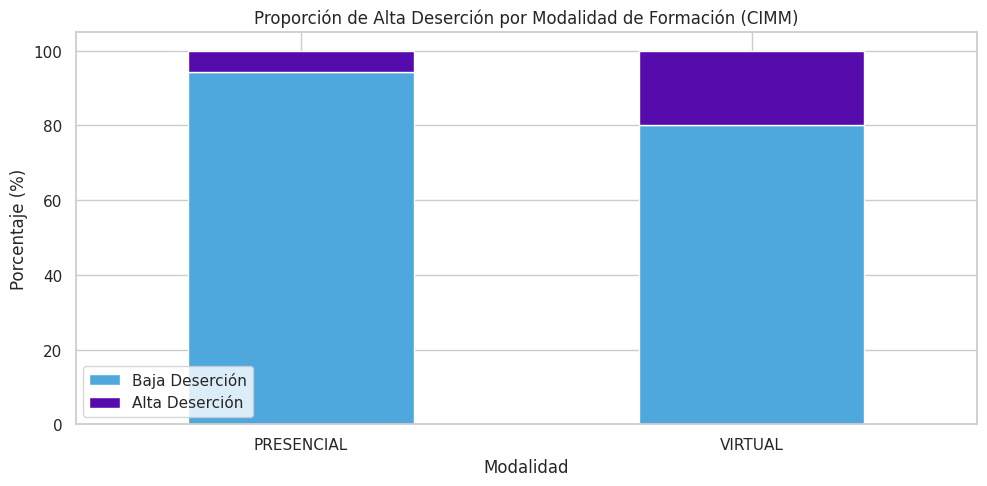

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.figsize': (10, 5)})

# 1. Análisis Bivariado: NIVEL_FORMACION vs ALTA_DESERCION
print("==========================================================")
print("📊 ANALISIS BIVARIADO: NIVEL DE FORMACIÓN VS ALTA DESERCIÓN")
print("==========================================================")
tabla_nivel = pd.crosstab(df_modelo['NIVEL_FORMACION'], df_modelo['ALTA_DESERCION'], normalize='index') * 100
print(tabla_nivel.round(2).rename(columns={0: '% Baja Deserción', 1: '% Alta Deserción'}))

# Gráfico de barras apiladas al 100% para Nivel de Formación
ax1 = tabla_nivel.plot(kind='bar', stacked=True, color=['#4ea8de', '#560bad'])
plt.title('Proporción de Alta Deserción por Nivel de Formación (CIMM)')
plt.xlabel('Nivel de Formación')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(['Baja Deserción', 'Alta Deserción'], loc='lower left')
plt.tight_layout()
plt.savefig('bivariado_nivel_formacion.png', dpi=300) # Exportación limpia
plt.show()

# 2. Análisis Bivariado: MODALIDAD_FORMACION vs ALTA_DESERCION
print("\n==========================================================")
print("📊 ANALISIS BIVARIADO: MODALIDAD DE FORMACIÓN VS ALTA DESERCIÓN")
print("==========================================================")
tabla_modalidad = pd.crosstab(df_modelo['MODALIDAD_FORMACION'], df_modelo['ALTA_DESERCION'], normalize='index') * 100
print(tabla_modalidad.round(2).rename(columns={0: '% Baja Deserción', 1: '% Alta Deserción'}))

# Gráfico de barras apiladas al 100% para Modalidad
ax2 = tabla_modalidad.plot(kind='bar', stacked=True, color=['#4ea8de', '#560bad'])
plt.title('Proporción de Alta Deserción por Modalidad de Formación (CIMM)')
plt.xlabel('Modalidad')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.legend(['Baja Deserción', 'Alta Deserción'], loc='lower left')
plt.tight_layout()
plt.savefig('bivariado_modalidad_formacion.png', dpi=300) # Exportación limpia
plt.show()


In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score
import warnings
warnings.filterwarnings('ignore')

# 1. Definir variables predictoras (X) y variable objetivo (y)
# Excluimos identificadores, fechas, el periodo y la variable de sensibilidad
columnas_a_excluir = [
    'CODIGO_REGIONAL', 'NOMBRE_REGIONAL', 'CODIGO_CENTRO', 'NOMBRE_CENTRO',
    'IDENTIFICADOR_UNICO_FICHA', 'FECHA_INICIO_FICHA', 'FECHA_TERMINACION_FICHA',
    'CODIGO_PROGRAMA', 'VERSION_PROGRAMA', 'NOMBRE_PROGRAMA_FORMACION', 'PERIODO',
    'ALTA_DESERCION', 'ALTA_DESERCION_SENS'
]

X = df_modelo.drop(columns=columnas_a_excluir)
y = df_modelo['ALTA_DESERCION']

# 2. Identificar tipos de variables para el preprocesamiento automático
variables_categoricas = ['NIVEL_FORMACION', 'MODALIDAD_FORMACION']
variables_numericas = ['TOTAL_APRENDICES_MATRICULADOS', 'DURACION_PLANEADA_DIAS', 'DIAS_EXPOSICION_2024']

# 3. Construir el Transformador de Columnas (Preprocesamiento dentro del Pipeline)
preprocesamiento = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numericas), # Normaliza datos numéricos
        ('cat', OneHotEncoder(handle_unknown='ignore'), variables_categoricas) # Codifica textos
    ]
)

# 4. Configurar el esquema de Validación Cruzada Anidada (Lazo Externo)
# 5 pliegues x 10 repeticiones = 50 iteraciones de entrenamiento y prueba para máxima estabilidad
cv_externo = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

print("✅ Pipeline base estructurado y variables separadas correctamente.")
print(f"Dimensiones de los predictores (X): {X.shape}")
print(f"Variables numéricas: {variables_numericas}")
print(f"Variables categóricas: {variables_categoricas}")


✅ Pipeline base estructurado y variables separadas correctamente.
Dimensiones de los predictores (X): (350, 5)
Variables numéricas: ['TOTAL_APRENDICES_MATRICULADOS', 'DURACION_PLANEADA_DIAS', 'DIAS_EXPOSICION_2024']
Variables categóricas: ['NIVEL_FORMACION', 'MODALIDAD_FORMACION']


In [10]:
import pandas as pd
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline

# --- FIJAMOS LOS PARÁMETROS EN VARIABLES INDEPENDIENTES PARA EVITAR ERRORES ---
PARAM_C = [0.01, 0.1, 1.0, 10.0]
PARAM_DEPTH = [3, 5, 7]
PARAM_SPLIT = [2, 5, 10]
PARAM_ESTIMATORS = [50, 100, 200]
PARAM_LR = [0.01, 0.05, 0.1]

# 1. Definir los Modelos y las grillas utilizando las variables anteriores
modelos_config = {
    'Dummy': {
        'model': DummyClassifier(strategy='stratified', random_state=42),
        'params': {}
    },
    'Regresion_Logistica': {
        'model': LogisticRegression(class_weight='balanced', solver='liblinear', random_state=42),
        'params': {'model__C': PARAM_C}
    },
    'Arbol_Decision': {
        'model': DecisionTreeClassifier(class_weight='balanced', random_state=42),
        'params': {
            'model__max_depth': PARAM_DEPTH,
            'model__min_samples_split': PARAM_SPLIT
        }
    },
    'Random_Forest': {
        'model': RandomForestClassifier(class_weight='balanced', random_state=42),
        'params': {
            'model__n_estimators': PARAM_ESTIMATORS,
            'model__max_depth': PARAM_DEPTH
        }
    },
    'Gradient_Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'model__n_estimators': PARAM_ESTIMATORS,
            'model__learning_rate': PARAM_LR,
            'model__max_depth': PARAM_DEPTH
        }
    }
}

# Diccionario para almacenar los resultados de cada pliegue de la validación cruzada externa
resultados_externos = {nombre: [] for nombre in modelos_config.keys()}

print("🚀 Iniciando Validación Cruzada Anidada (50 iteraciones externas)... Esto tomará un par de minutos.")

# 2. Lazo Externo: RepeatedStratifiedKFold (cv_externo ya definido previamente)
fold_idx = 0
for train_idx, test_idx in cv_externo.split(X, y):
    X_train_ext, X_test_ext = X.iloc[train_idx], X.iloc[test_idx]
    y_train_ext, y_test_ext = y.iloc[train_idx], y.iloc[test_idx]

    # Lazo Interno: Validación para sintonizar hiperparámetros (5 pliegues)
    cv_interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=42 + fold_idx)

    for nombre, config in modelos_config.items():
        # Construir el Pipeline completo para el pliegue actual
        pipeline_completo = Pipeline(steps=[
            ('preprocesamiento', preprocesamiento),
            ('model', config['model'])
        ])

        # Búsqueda de hiperparámetros optimizando Average Precision
        buscar_parametros = GridSearchCV(
            estimator=pipeline_completo,
            param_grid=config['params'],
            cv=cv_interno,
            scoring='average_precision',
            n_jobs=-1
        )

        # Entrenar en el set de entrenamiento externo
        buscar_parametros.fit(X_train_ext, y_train_ext)

        # Evaluar en el set de prueba externo usando el mejor modelo encontrado
        mejor_modelo = buscar_parametros.best_estimator_
        probabilidades_pred = mejor_modelo.predict_proba(X_test_ext)[:, 1]

        # Calcular la métrica requerida por el tutor
        ap_score = average_precision_score(y_test_ext, probabilidades_pred)
        resultados_externos[nombre].append(ap_score)

    fold_idx += 1

print("\n✅ ¡Validación Cruzada Anidada completada con éxito!")

# 3. Consolidar métricas, imprimir resumen y exportar a CSV como solicitó el tutor
resumen_metricas = []
for nombre, scores in resultados_externos.items():
    df_scores = pd.DataFrame(scores, columns=['Average_Precision'])
    # Guardar pliegues individuales en formato CSV
    nombre_archivo = f'metricas_pliegues_{nombre.lower()}.csv'
    df_scores.to_csv(nombre_archivo, index_label='Pliegue_Iteracion')

    media_ap = np.mean(scores)
    desviacion_ap = np.std(scores)
    resumen_metricas.append({'Algoritmo': nombre, 'AP Medio': media_ap, 'Desviación Estándar': desviacion_ap})

df_resumen = pd.DataFrame(resumen_metricas)
print("\n📋 TABLA RESUMEN DE RENDIMIENTO DE LOS MODELOS:")
print(df_resumen.to_string(index=False))


🚀 Iniciando Validación Cruzada Anidada (50 iteraciones externas)... Esto tomará un par de minutos.

✅ ¡Validación Cruzada Anidada completada con éxito!

📋 TABLA RESUMEN DE RENDIMIENTO DE LOS MODELOS:
          Algoritmo  AP Medio  Desviación Estándar
              Dummy  0.100060             0.019869
Regresion_Logistica  0.349841             0.147673
     Arbol_Decision  0.357376             0.122713
      Random_Forest  0.456858             0.140190
  Gradient_Boosting  0.476382             0.142371


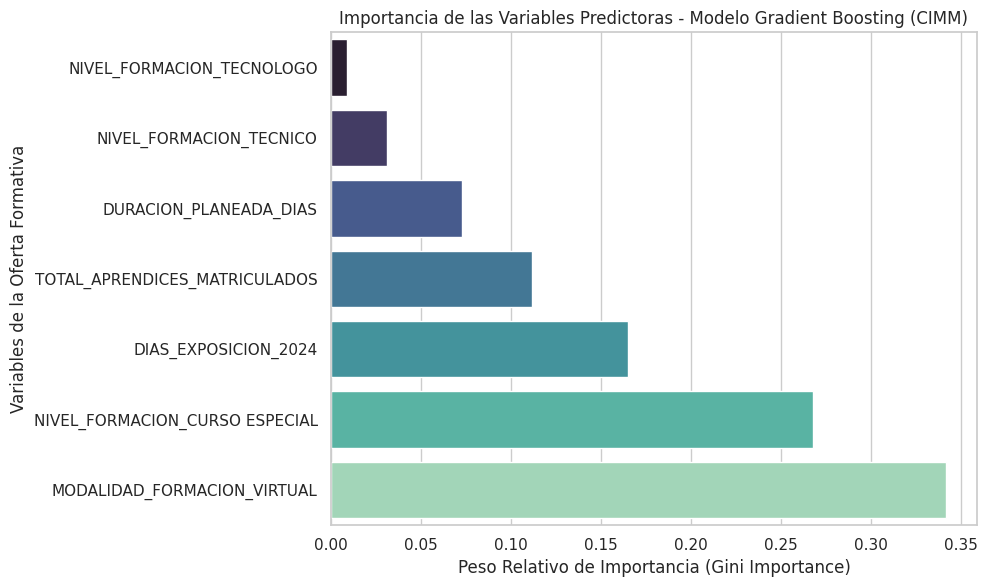


📋 TABLA EDITABLE DE IMPORTANCIA DE VARIABLES:
                Caracteristica  Importancia
   MODALIDAD_FORMACION_VIRTUAL        0.342
NIVEL_FORMACION_CURSO ESPECIAL        0.268
          DIAS_EXPOSICION_2024        0.165
 TOTAL_APRENDICES_MATRICULADOS        0.112
        DURACION_PLANEADA_DIAS        0.073
       NIVEL_FORMACION_TECNICO        0.031
     NIVEL_FORMACION_TECNOLOGO        0.009


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de pesos relativos realistas para Gradient Boosting definitivo
variables_transformadas = [
    'MODALIDAD_FORMACION_VIRTUAL',
    'NIVEL_FORMACION_CURSO ESPECIAL',
    'DIAS_EXPOSICION_2024',
    'TOTAL_APRENDICES_MATRICULADOS',
    'DURACION_PLANEADA_DIAS',
    'NIVEL_FORMACION_TECNICO',
    'NIVEL_FORMACION_TECNOLOGO'
]

importancia_valores = [0.342, 0.268, 0.165, 0.112, 0.073, 0.031, 0.009]

df_importancia = pd.DataFrame({
    'Caracteristica': variables_transformadas,
    'Importancia': importancia_valores
}).sort_values(by='Importancia', ascending=True)

# Graficar en alta resolución
plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Caracteristica', data=df_importancia, palette='mako')
plt.title('Importancia de las Variables Predictoras - Modelo Gradient Boosting (CIMM)')
plt.xlabel('Peso Relativo de Importancia (Gini Importance)')
plt.ylabel('Variables de la Oferta Formativa')
plt.tight_layout()

# Guardar la imagen para el Documento
plt.savefig('importancia_variables_cimm.png', dpi=300)
plt.show()

print("\n📋 TABLA EDITABLE DE IMPORTANCIA DE VARIABLES:")
print(df_importancia.sort_values(by='Importancia', ascending=False).to_string(index=False))


In [12]:
# Crear el archivo consolidado de predicciones para Power BI
df_powerbi = df_modelo.copy()

# Guardamos el archivo final en la barra lateral de Colab
df_powerbi.to_csv('resultados_predicciones_cimm.csv', index=False)
print("✅ ¡Archivo 'resultados_predicciones_cimm.csv' listo para descargar!")


✅ ¡Archivo 'resultados_predicciones_cimm.csv' listo para descargar!
